# B5. Integrasi: Rangkaian Praproses SIMUTEH
Menyusun `src/praproses.py`, membandingkan konfigurasi dengan KB pada kanal R, menguji bercak palsu pada daun sehat, lalu menyimpan parameter final, README, dan ZIP kode.

In [2]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [3]:
# Pastikan B1 sudah dijalankan di akun/folder yang sama
for p in ["../src/utils_cv.py", "../data/sintetis/label.csv"]:
    assert os.path.exists(p), f"{p} tidak ditemukan. Jalankan B1 (Run all) di akun dan folder yang sama dulu."
print("Prasyarat dari B1 lengkap.")

# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

Prasyarat dari B1 lengkap.


## Kode 5.1: modul `src/praproses.py`

In [4]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,             # sampling: lebar citra kerja (piksel)
    "gamma": "auto",          # angka tetap, atau "auto" (dipilih dari statistik kanal V)
    "gamma_terang": 1.6,      # dipakai bila gamma = "auto" dan citra terang
    "gamma_gelap": 1.0,       # dipakai bila gamma = "auto" dan citra gelap (1.0 = dibiarkan)
    "clahe_clip": 1.0,        # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 4,
    "clahe_otomatis": True,   # True: CLAHE hanya bila cahaya terdeteksi tidak merata
    "batas_tidak_rata": 0.65, # ambang indeks ketidakrataan cahaya
    "penapis": "median",      # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,           # 0 berarti tanpa penajaman
}


def _kanal_v(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2]


def gamma_otomatis(img_bgr, gamma_terang=1.6, gamma_gelap=1.0):
    """Memilih gamma dari statistik kanal V. Ambang diturunkan dari statistik 60 citra
    sintetis: terang (rerata V > 210) -> gamma_terang; kontras rendah (simp. baku V < 20)
    -> 1.0; gelap (persentil 95 V < 200) -> gamma_gelap; selain itu -> 1.0."""
    v = _kanal_v(img_bgr)
    if v.mean() > 210:
        return gamma_terang
    if v.std() < 20:
        return 1.0
    if np.percentile(v, 95) < 200:
        return gamma_gelap
    return 1.0


def indeks_ketidakrataan(img_bgr):
    """Ketidakrataan cahaya: citra dibagi 4 x 4 blok, kecerahan tiap blok diwakili
    persentil 90 kanal V (didominasi latar nampan), lalu (maks - min) / rerata."""
    v = _kanal_v(img_bgr).astype(float)
    h, w = v.shape
    blok = [np.percentile(v[i * h // 4:(i + 1) * h // 4, j * w // 4:(j + 1) * w // 4], 90)
            for i in range(4) for j in range(4)]
    return (max(blok) - min(blok)) / np.mean(blok)


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. ubah ukuran, rasio aspek tetap
    h, w = img_bgr.shape[:2]
    img = cv2.resize(img_bgr, (p["lebar"], int(round(h * p["lebar"] / w))),
                     interpolation=cv2.INTER_AREA)

    # 2. koreksi gamma dengan lookup table
    g = (gamma_otomatis(img, p["gamma_terang"], p["gamma_gelap"])
         if p["gamma"] == "auto" else float(p["gamma"]))
    if g != 1.0:
        lut = np.clip(255 * (np.arange(256) / 255) ** g, 0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)

    # 3. CLAHE hanya pada kanal V agar warna tidak bergeser
    pakai = p["clahe_clip"] > 0
    if pakai and p["clahe_otomatis"]:
        pakai = indeks_ketidakrataan(img) > p["batas_tidak_rata"]
    if pakai:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. redam derau
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)

    # 5. tajamkan (unsharp masking) bila diminta
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing ../src/praproses.py


In [5]:
import importlib, praproses as pp
importlib.reload(pp)
img, md, mb = muat("teh_041.png")
hasil = pp.praproses(img)
print("masukan:", img.shape, "-> keluaran:", hasil.shape, hasil.dtype)
print("gamma terpilih:", pp.gamma_otomatis(cv2.resize(img, (640, 480))), "| indeks ketidakrataan:", round(pp.indeks_ketidakrataan(img), 2))

masukan: (480, 640, 3) -> keluaran: (480, 640, 3) uint8
gamma terpilih: 1.0 | indeks ketidakrataan: 0.25


## Statistik penentu gamma dan CLAHE otomatis (60 citra)

In [6]:
baris = []
for _, d in label.iterrows():
    im, _, _ = muat(d.nama_file)
    v = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[:, :, 2]
    baris.append([d.kondisi_cahaya, v.mean(), v.std(), np.percentile(v, 95), pp.indeks_ketidakrataan(im)])
stat_v = pd.DataFrame(baris, columns=["kondisi", "rerata_V", "std_V", "p95_V", "indeks_tidak_rata"])
urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
ringkas_v = stat_v.groupby("kondisi").agg(["min", "max"]).round(2).reindex(urutan)
display(ringkas_v); ringkas_v.to_csv("../hasil/b5_statistik_penentu.csv")

rerata_V          std_V         p95_V        indeks_tidak_rata      
                    min     max    min    max    min    max               min   max
kondisi                                                                            
normal           179.79  199.59  26.54  38.40  206.0  232.0              0.25  0.38
gelap            125.51  155.65  30.62  45.36  157.0  197.0              0.08  0.54
terang           218.66  228.17  13.39  23.04  235.0  255.0              0.09  0.18
kontras_rendah   161.86  167.57  11.12  17.07  177.0  191.0              0.08  0.15
bayangan         134.33  141.88  49.53  59.44  220.0  243.0              0.78  0.91

## Kode 5.2: perbandingan konfigurasi pada kanal R (40 citra berbercak)

In [7]:
KANAL = 2        # indeks BGR: 2 = R, kanal terbaik dari B2
konfigurasi = {
    "A contoh petunjuk (CLAHE 2/8 selalu)": dict(gamma=1.0, clahe_clip=2.0, clahe_tile=8, clahe_otomatis=False),
    "B hanya median 3":                      dict(gamma=1.0, clahe_clip=0),
    "C gamma gelap 0,6 + terang 1,6":        dict(gamma_gelap=0.6, clahe_clip=0),
    "D gamma hanya terang (1,6)":            dict(clahe_clip=0),
    "E D + CLAHE 1/4 otomatis (FINAL)":      dict(),
    "F CLAHE 1/4 selalu":                    dict(clahe_otomatis=False),
    "G final dengan median 5":               dict(kernel=5),
}
berbercak = label[label.kelas != "sehat"]
kb_sebelum = {}
hasil_kb = {}
for nm, p in konfigurasi.items():
    baris = []
    for _, d in berbercak.iterrows():
        im, m_d, m_b = muat(d.nama_file)
        out = pp.praproses(im, p)
        baris.append([d.kondisi_cahaya, kontras_bercak(im[:, :, KANAL], m_d, m_b), kontras_bercak(out[:, :, KANAL], m_d, m_b)])
    t = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"]).groupby("kondisi").mean().reindex(urutan)
    hasil_kb[nm] = t

banding = pd.DataFrame({nm: t.KB_sesudah for nm, t in hasil_kb.items()}).T
banding.loc["(sebelum praproses)"] = hasil_kb["B hanya median 3"].KB_sebelum
banding = banding.reindex(["(sebelum praproses)"] + list(konfigurasi))
banding["rerata"] = banding.mean(axis=1)
banding = banding.round(2)
print("KB kanal R sesudah praproses, menurut konfigurasi dan kondisi")
display(banding); banding.to_csv("../hasil/b5_banding_konfigurasi.csv")

KB kanal R sesudah praproses, menurut konfigurasi dan kondisi


kondisi,normal,gelap,terang,kontras_rendah,bayangan,rerata
(sebelum praproses),10.18,9.11,7.59,3.90,4.14,6.98
A contoh petunjuk (CLAHE 2/8 selalu),11.90,15.15,6.17,4.85,6.98,9.01
B hanya median 3,15.40,16.09,11.40,8.02,5.02,11.18
"C gamma gelap 0,6 + terang 1,6",15.40,10.25,12.75,8.02,5.02,10.29
"D gamma hanya terang (1,6)",15.40,16.09,12.75,8.02,5.02,11.45
E D + CLAHE 1/4 otomatis (FINAL),15.40,16.09,12.75,8.02,6.91,11.83
F CLAHE 1/4 selalu,14.34,16.21,11.17,7.34,6.91,11.19
G final dengan median 5,16.55,18.31,13.47,10.13,6.95,13.08


In [8]:
# Tabel 12: konfigurasi final
PARAM_FINAL = {"lebar": 640, "gamma": "auto", "gamma_terang": 1.6, "gamma_gelap": 1.0,
               "clahe_clip": 1.0, "clahe_tile": 4, "clahe_otomatis": True, "batas_tidak_rata": 0.65,
               "penapis": "median", "kernel": 3, "sigma": 1.0, "tajam_k": 0.0}
tab12 = hasil_kb["E D + CLAHE 1/4 otomatis (FINAL)"].copy()
tab12["perubahan_%"] = (100 * (tab12.KB_sesudah / tab12.KB_sebelum - 1)).round(1)
tab12 = tab12.round(2)
print("Tabel 12: evaluasi rangkaian final"); display(tab12); tab12.to_csv("../hasil/b5_tabel12_evaluasi.csv")
pp.simpan_param(PARAM_FINAL, "../hasil/param_praproses.json")
print(open("../hasil/param_praproses.json").read())

Tabel 12: evaluasi rangkaian final


,KB_sebelum,KB_sesudah,perubahan_%
kondisi,,,
normal,10.18,15.40,51.3
gelap,9.11,16.09,76.5
terang,7.59,12.75,67.9
kontras_rendah,3.90,8.02,105.9
bayangan,4.14,6.91,66.8


{
  "lebar": 640,
  "gamma": "auto",
  "gamma_terang": 1.6,
  "gamma_gelap": 1.0,
  "clahe_clip": 1.0,
  "clahe_tile": 4,
  "clahe_otomatis": true,
  "batas_tidak_rata": 0.65,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


## Langkah 5.3: uji bercak palsu pada 20 citra sehat

Konfigurasi FINAL, rerata per kondisi


,std_sebelum,std_sesudah,terang_sebelum_%,terang_sesudah_%
kondisi,,,,
normal,12.57,7.41,0.45,2.42
gelap,9.70,5.51,0.18,1.68
terang,11.48,7.34,0.37,2.17
kontras_rendah,9.58,4.43,0.01,0.87
bayangan,13.10,8.52,0.24,0.72


Rerata semua kondisi menurut konfigurasi


,std_sebelum,std_sesudah,terang_sebelum_%,terang_sesudah_%
konfigurasi,,,,
A contoh petunjuk (CLAHE 2/8 selalu),11.29,9.80,0.25,1.41
B hanya median 3,11.29,6.72,0.25,1.49
"C gamma gelap 0,6 + terang 1,6",11.29,7.82,0.25,1.36
"D gamma hanya terang (1,6)",11.29,6.90,0.25,1.51
E D + CLAHE 1/4 otomatis (FINAL),11.29,6.64,0.25,1.57
F CLAHE 1/4 selalu,11.29,7.17,0.25,2.13
G final dengan median 5,11.29,5.69,0.25,2.84


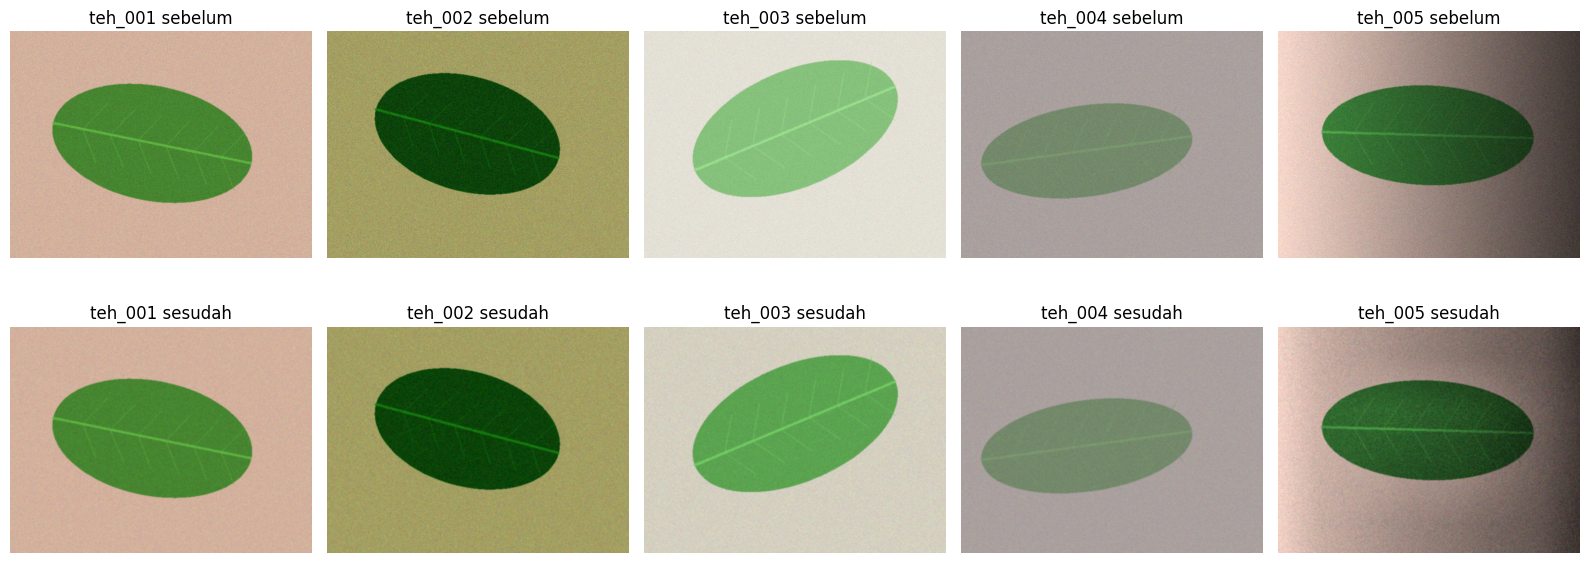

In [9]:
def ukuran_daun(x, m):
    """Simpangan baku kanal terpilih di area daun, dan persen piksel daun yang lebih terang dari median + 4 x MAD."""
    c = x[:, :, KANAL].astype(float)[m]
    med = np.median(c); mad = 1.4826 * np.median(np.abs(c - med))
    return c.std(), 100 * (c > med + 4 * mad).mean()

sehat = label[label.kelas == "sehat"]
baris = []
for nm_k, p in konfigurasi.items():
    for _, d in sehat.iterrows():
        im, m_d, _ = muat(d.nama_file)
        out = pp.praproses(im, p)
        a, b = ukuran_daun(im, m_d > 0), ukuran_daun(out, m_d > 0)
        baris.append([nm_k, d.kondisi_cahaya, a[0], b[0], a[1], b[1]])
uji_sehat = pd.DataFrame(baris, columns=["konfigurasi", "kondisi", "std_sebelum", "std_sesudah", "terang_sebelum_%", "terang_sesudah_%"])

final = uji_sehat[uji_sehat.konfigurasi.str.contains("FINAL")].drop(columns="konfigurasi").groupby("kondisi").mean().reindex(urutan).round(2)
print("Konfigurasi FINAL, rerata per kondisi"); display(final); final.to_csv("../hasil/b5_uji_sehat_final.csv")
print("Rerata semua kondisi menurut konfigurasi")
display(uji_sehat.drop(columns="kondisi").groupby("konfigurasi").mean().round(2))

# panel sebelum dan sesudah, satu citra sehat per kondisi
pilih = [sehat[sehat.kondisi_cahaya == k].nama_file.iloc[0] for k in urutan]
atas, bawah = [], []
for nm in pilih:
    im, _, _ = muat(nm); atas.append(im); bawah.append(pp.praproses(im, PARAM_FINAL))
tampil(atas + bawah, [f"{n[:7]} sebelum" for n in pilih] + [f"{n[:7]} sesudah" for n in pilih], baris=2, ukuran=(16, 6.5))
plt.savefig("../hasil/b5_panel_sehat.png", dpi=110); plt.show()

## Langkah 5.4: justifikasi dan diagram rangkaian final

,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,"lebar 640 px, INTER_AREA","Citra kerja sama dengan ukuran mask acuan; konvolusi 5x5 pada 640x480 sekitar 39 kali lebih ringan daripada 4000x3000 (B4, P4.6)","Terlalu kecil: bercak kecil hilang (B2, Kode 2.2)"
1,2. Koreksi gamma,"otomatis; terang 1,6; gelap dibiarkan (1,0)","Pada kondisi gelap, gamma 0,6 menurunkan KB R (16.09 menjadi 10.25); pada kondisi terang gamma 1,6 menaikkannya (11.40 menjadi 12.75)",Gamma salah arah menekan kontras bercak atau menaikkan keragaman daun sehat
2,3. CLAHE kanal V,"clip 1, tile 4, hanya bila indeks tidak rata > 0,65",Indeks tidak rata kondisi bayangan jauh di atas kondisi lain (tabel statistik); pada bayangan KB R naik (5.02 menjadi 6.91); CLAHE 2/8 selalu (konfigurasi A) memberi KB normal lebih rendah (11.90 ...,Clip besar atau CLAHE selalu aktif memperbesar derau dan memunculkan titik terang pada daun sehat
3,4. Redam derau,"median, kernel 3","Median 3 menjaga bercak kecil (B4, Kode 4.3). Median 5 menaikkan KB (rerata 13.08 vs 11.83) tetapi kernel lebih besar berisiko menghapus bercak ringan",Kernel terlalu besar menghapus bercak ringan; terlalu kecil menyisakan derau
4,5. Tajamkan,tidak dipakai (k = 0),"KB sudah naik tanpa penajaman (Tabel 12), sedangkan penajaman ikut menguatkan sisa derau; urutan redam lalu tajam diuji pada B4 Kode 4.4",Memunculkan bercak palsu pada daun sehat


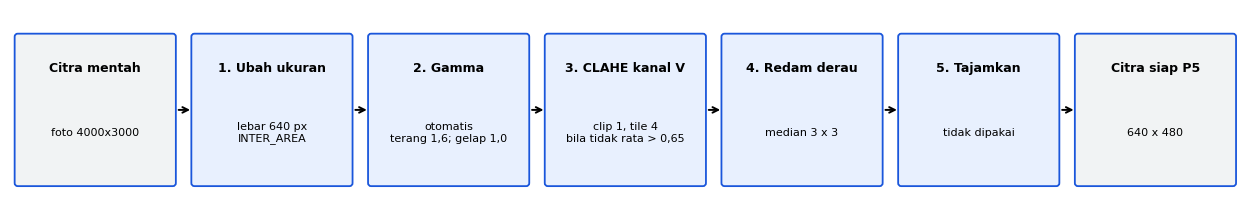

In [10]:
kb = lambda nm, k: hasil_kb[nm].KB_sesudah[k]
B, C, E, G, A = ("B hanya median 3", "C gamma gelap 0,6 + terang 1,6", "E D + CLAHE 1/4 otomatis (FINAL)",
                 "G final dengan median 5", "A contoh petunjuk (CLAHE 2/8 selalu)")
justifikasi = pd.DataFrame([
 ["1. Ubah ukuran", "lebar 640 px, INTER_AREA",
  "Citra kerja sama dengan ukuran mask acuan; konvolusi 5x5 pada 640x480 sekitar 39 kali lebih ringan daripada 4000x3000 (B4, P4.6)",
  "Terlalu kecil: bercak kecil hilang (B2, Kode 2.2)"],
 ["2. Koreksi gamma", "otomatis; terang 1,6; gelap dibiarkan (1,0)",
  f"Pada kondisi gelap, gamma 0,6 menurunkan KB R ({kb(B,'gelap'):.2f} menjadi {kb(C,'gelap'):.2f}); pada kondisi terang gamma 1,6 menaikkannya ({kb(B,'terang'):.2f} menjadi {banding.loc['D gamma hanya terang (1,6)','terang']:.2f})",
  "Gamma salah arah menekan kontras bercak atau menaikkan keragaman daun sehat"],
 ["3. CLAHE kanal V", "clip 1, tile 4, hanya bila indeks tidak rata > 0,65",
  f"Indeks tidak rata kondisi bayangan jauh di atas kondisi lain (tabel statistik); pada bayangan KB R naik ({banding.loc['D gamma hanya terang (1,6)','bayangan']:.2f} menjadi {kb(E,'bayangan'):.2f}); CLAHE 2/8 selalu (konfigurasi A) memberi KB normal lebih rendah ({kb(A,'normal'):.2f} vs {kb(E,'normal'):.2f})",
  "Clip besar atau CLAHE selalu aktif memperbesar derau dan memunculkan titik terang pada daun sehat"],
 ["4. Redam derau", "median, kernel 3",
  f"Median 3 menjaga bercak kecil (B4, Kode 4.3). Median 5 menaikkan KB (rerata {banding.loc[G,'rerata']:.2f} vs {banding.loc[E,'rerata']:.2f}) tetapi kernel lebih besar berisiko menghapus bercak ringan",
  "Kernel terlalu besar menghapus bercak ringan; terlalu kecil menyisakan derau"],
 ["5. Tajamkan", "tidak dipakai (k = 0)",
  "KB sudah naik tanpa penajaman (Tabel 12), sedangkan penajaman ikut menguatkan sisa derau; urutan redam lalu tajam diuji pada B4 Kode 4.4",
  "Memunculkan bercak palsu pada daun sehat"],
], columns=["Langkah", "Parameter final", "Alasan dan bukti", "Risiko bila salah atur"])
pd.set_option("display.max_colwidth", 200)
display(justifikasi); justifikasi.to_csv("../hasil/b5_tabel13_justifikasi.csv", index=False)

from matplotlib.patches import FancyBboxPatch
kotak = [("Citra mentah", "foto 4000x3000"), ("1. Ubah ukuran", "lebar 640 px\nINTER_AREA"),
         ("2. Gamma", "otomatis\nterang 1,6; gelap 1,0"), ("3. CLAHE kanal V", "clip 1, tile 4\nbila tidak rata > 0,65"),
         ("4. Redam derau", "median 3 x 3"), ("5. Tajamkan", "tidak dipakai"), ("Citra siap P5", "640 x 480")]
fig, ax = plt.subplots(figsize=(16, 2.6)); ax.set_xlim(0, 16); ax.set_ylim(0, 2.6); ax.axis("off")
for i, (jd, ket) in enumerate(kotak):
    x = 0.1 + i * 2.28
    ax.add_patch(FancyBboxPatch((x, 0.35), 2.0, 1.9, boxstyle="round,pad=0.04", fc="#e8f0fe" if 0 < i < 6 else "#f1f3f4", ec="#1a56db", lw=1.3))
    ax.text(x + 1.0, 1.8, jd, ha="center", fontweight="bold", fontsize=9)
    ax.text(x + 1.0, 1.0, ket, ha="center", va="center", fontsize=8)
    if i < 6: ax.annotate("", xy=(x + 2.26, 1.3), xytext=(x + 2.04, 1.3), arrowprops=dict(arrowstyle="->", lw=1.4))
plt.savefig("../hasil/b5_diagram_praproses.png", dpi=130, bbox_inches="tight"); plt.show()

## Langkah 5.5: README dan ZIP kode

In [11]:
import shutil
ringkas_md = tab12[["KB_sebelum", "KB_sesudah", "perubahan_%"]].to_string()
readme = f"""# SIMUTEH - Evaluasi Praktikum P1-P4 Computer Vision
Nama: {NAMA} | NIM: {NIM} | Kelas: {KELAS} | SEED: {SEED}

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Dari folder utama: `python src/buat_dataset_sintetis.py` (SEED = {SEED})
3. Jalankan notebook B1 sampai B5 di folder `notebook/` berurutan dengan Restart & Run All.

## Rangkaian praproses final (`hasil/param_praproses.json`)
ubah ukuran 640 px -> gamma otomatis (terang 1,6; gelap dibiarkan) -> CLAHE kanal V (clip 1, tile 4, hanya bila cahaya tidak rata) -> median 3 x 3; tanpa penajaman.

## Ringkasan KB kanal R (rerata 40 citra berbercak)
```
{ringkas_md}
```
"""
open("../README.md", "w").write(readme)

staging = f"{ROOT}/laporan/_zip"
shutil.rmtree(staging, ignore_errors=True)
for sub in ["src", "hasil"]:
    shutil.copytree(f"{ROOT}/{sub}", f"{staging}/{sub}")
os.makedirs(f"{staging}/notebook", exist_ok=True)
for f in os.listdir(f"{ROOT}/notebook"):
    if f.endswith(".ipynb"): shutil.copy(f"{ROOT}/notebook/{f}", f"{staging}/notebook/{f}")
for f in ["requirements.txt", "README.md"]:
    shutil.copy(f"{ROOT}/{f}", f"{staging}/{f}")
arsip = shutil.make_archive(f"{ROOT}/laporan/Kode_EvalP1-4_{NIM}", "zip", staging)
shutil.rmtree(staging)
print("ZIP dibuat:", arsip)

ZIP dibuat: /content/drive/MyDrive/simuteh-2330511007/laporan/Kode_EvalP1-4_2330511007.zip
